# Fuerte vs débil suave vs totalmente débil (L0)

Mismo problema que `wpinn_simple.ipynb`: choque móvil de Burgers 2D,

$$u_t + \partial_x\Big(\tfrac{u^2}{2}\Big) + \partial_y\Big(\tfrac{u^2}{2}\Big) = 0, \qquad (x,y) \in [-1,1]^2, \quad t \in [0, 0.5],$$

con $u_0 = 1$ si $x \le 0$ y $u_0 = 0$ si $x > 0$. La solución exacta es un escalón en $x = t/2$.

**Pregunta del notebook.** La forma débil existe para **no derivar $u$**, que salta. Pero la wPINN de
`wpinn_simple` (y la discretización $R_{int}$ del paper) usa $u_t$. ¿Cambia algo quitar esa derivada?

Se comparan tres pérdidas, todas al nivel L0 (sin L1 ni L2), con $Q(u,c) = \mathrm{sign}(u-c)\,(H(u) - H(c))$:

| Método | Residual | Deriva $u$ | Deriva $\varphi$ |
|---|---|---|---|
| fuerte (PINN) | $u_t + u\,(u_x + u_y)$, al cuadrado | $u_t, u_x, u_y$ | — |
| débil suave (`wpinn_simple`) | $\iint \varphi\,\mathrm{sign}(u-c)\,u_t - Q\,(\varphi_x + \varphi_y)$ | $u_t$ | $\varphi_x, \varphi_y$ |
| totalmente débil (ec. 10) | $-\iint |u-c|\,\varphi_t + Q\,(\varphi_x + \varphi_y)$ | nada | $\varphi_t, \varphi_x, \varphi_y$ |

Las dos débiles son iguales salvo una integración por partes en $t$:

$$\iint \varphi\,\partial_t|u-c| = -\iint |u-c|\,\varphi_t + \int_\Omega \big[\varphi\,|u-c|\big]_{t=0}^{t=T}.$$

La ec. 10 no tiene el último término, así que **$\varphi$ debe anularse en $t = 0$ y $t = T$**. Por eso
la débil total usa la ventana $t\,(T - t)\,(1-x^2)(1-y^2)$ y la suave sólo $(1-x^2)(1-y^2)$, como en
`wpinn_simple`. El dato inicial entra en las tres por la pérdida de datos, igual que antes.

## 1. Montaje

Las piezas son las de `wpinn_simple`, recortadas a L0: sin L1, L2, muestreadores ni interruptores de casos borde.

### 1.1 Librerías y configuración

In [25]:
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Semilla fija para que dos corridas den lo mismo.
torch.manual_seed(0)
np.random.seed(0)

# GPU si hay, si no CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


### 1.2 El problema: choque móvil

In [26]:
# Dominio: x e y en [-1, 1], tiempo en [0, T].
x_min, x_max = -1.0, 1.0
y_min, y_max = -1.0, 1.0
T = 1

# Volumen del dominio espacio-temporal |D| = 2 * 2 * 0.5 = 2.
# Sirve para pasar de un promedio Monte Carlo a una integral.
volume = (x_max - x_min) * (y_max - y_min) * T

# Flujo de Burgers. Es el mismo en x y en y.
def flux(u):
    return 0.5 * u**2

# Derivada del flujo, H'(u) = u. Sólo la usa el residual fuerte (regla de la cadena: H(u)_x = H'(u) u_x).
def flux_derivative(u):
    return u

# Dato inicial: 1 a la izquierda de x = 0, 0 a la derecha. No depende de y.
def initial_condition(x):
    return torch.where(x <= 0.0, 1.0, 0.0)

# Velocidad del choque (Rankine-Hugoniot): s = (H(1) - H(0)) / (1 - 0) = 1/2.
shock_speed = 0.5

# Solución exacta en numpy, sólo para comparar al final.
def exact_solution(x, t):
    return np.where(x <= shock_speed * t, 1.0, 0.0)

### 1.3 Las redes

- $u_\theta(x,y,t)$: 6 capas ocultas de 20 neuronas (como el paper). La misma en los tres métodos.
- $\xi_\eta(x,y,t)$: red de la función test, 4 capas de 10. La fuerte no la usa.

In [27]:
def build_network(n_hidden_layers, width):
    # Red totalmente conectada con tanh: entra (x, y, t), sale un número.
    layers = [nn.Linear(3, width), nn.Tanh()]
    for _ in range(n_hidden_layers - 1):
        layers += [nn.Linear(width, width), nn.Tanh()]
    layers.append(nn.Linear(width, 1))  # sin activación al final: la salida puede valer cualquier cosa
    return nn.Sequential(*layers).to(device)


# Red de la función test. train la reconstruye en cada entrenamiento con la semilla del método,
# así que esta primera versión sólo existe para que las funciones de abajo tengan algo que leer.
test_network = build_network(n_hidden_layers=4, width=10)
print(test_network)

Sequential(
  (0): Linear(in_features=3, out_features=10, bias=True)
  (1): Tanh()
  (2): Linear(in_features=10, out_features=10, bias=True)
  (3): Tanh()
  (4): Linear(in_features=10, out_features=10, bias=True)
  (5): Tanh()
  (6): Linear(in_features=10, out_features=10, bias=True)
  (7): Tanh()
  (8): Linear(in_features=10, out_features=1, bias=True)
)


### 1.4 Puntos de colocación

Iguales a los de `wpinn_simple`: interiores uniformes, dato inicial en $t = 0$, Dirichlet en $x = \pm 1$
(el choque nunca llega ahí) y condición periódica en $y = \pm 1$ (el choque atraviesa esas caras).

In [28]:
def sample_interior_points(n_points):
    # Uniformes en la caja [-1, 1] x [-1, 1] x [0, T].
    x = x_min + (x_max - x_min) * torch.rand(n_points, 1)
    y = y_min + (y_max - y_min) * torch.rand(n_points, 1)
    t = T * torch.rand(n_points, 1)
    return torch.cat([x, y, t], dim=1).to(device)


def sample_face_points(n_points, column, value):
    # Puntos sobre una cara: sorteo en toda la caja y luego "pego" una coordenada a la cara.
    points = sample_interior_points(n_points)
    points[:, column] = value
    return points


n_interior = 16000
n_initial = 2000
n_boundary = 2000   # la mitad en x = -1 y la mitad en x = 1
n_periodic = 1000   # pares (y = -1, y = 1)

interior_points = sample_interior_points(n_interior)
# requires_grad para poder derivar u y phi respecto a (x, y, t).
interior_points.requires_grad_(True)

# t es la columna 2: t = 0 es el dato inicial.
initial_points = sample_face_points(n_initial, column=2, value=0.0)
initial_values = initial_condition(initial_points[:, 0:1])

# Caras x = -1 y x = 1: Dirichlet con el dato inicial. El choque (x = t/2 <= 0.25) nunca llega aquí.
left_face_points = sample_face_points(n_boundary // 2, column=0, value=x_min)
right_face_points = sample_face_points(n_boundary // 2, column=0, value=x_max)
boundary_points = torch.cat([left_face_points, right_face_points], dim=0)
boundary_values = initial_condition(boundary_points[:, 0:1])

# Caras y = -1 e y = 1: periódica. Los dos puntos de cada par comparten x y t.
periodic_bottom_points = sample_face_points(n_periodic, column=1, value=y_min)
periodic_top_points = periodic_bottom_points.clone()
periodic_top_points[:, 1] = y_max


def data_losses(u_network):
    # Pérdidas de datos: (inicial, frontera). La de frontera suma Dirichlet en x y periódica en y.
    # Son idénticas en los tres métodos: lo único que cambia entre ellos es el término físico.
    initial_loss = ((u_network(initial_points) - initial_values) ** 2).mean()
    dirichlet_loss = ((u_network(boundary_points) - boundary_values) ** 2).mean()
    periodic_loss = ((u_network(periodic_bottom_points) - u_network(periodic_top_points)) ** 2).mean()
    return initial_loss, dirichlet_loss + periodic_loss


print(interior_points.shape, initial_points.shape, boundary_points.shape, periodic_bottom_points.shape)

torch.Size([16000, 3]) torch.Size([2000, 3]) torch.Size([2000, 3]) torch.Size([1000, 3])


### 1.5 Constantes de Kruzhkov

9 valores de $c$ entre $-0.25$ y $1.25$, como en `wpinn_simple`.

In [29]:
# Forma (1, 9) para que u - c, con u de forma (N, 1), dé (N, 9): una columna por c.
c = torch.linspace(-0.25, 1.25, 9, device=device).reshape(1, -1)
print(c)

tensor([[-0.2500, -0.0625,  0.1250,  0.3125,  0.5000,  0.6875,  0.8750,  1.0625,
          1.2500]], device='cuda:0')


### 1.6 Los tres residuales

- **Fuerte**: $f = u_t + H'(u)\,(u_x + u_y)$ en cada punto; la pérdida es la media de $f^2$.
- **Débil suave**: el integrando de `wpinn_simple`, $\varphi\,\mathrm{sign}(u-c)\,u_t - Q\,(\varphi_x + \varphi_y)$.
- **Totalmente débil**: el integrando de la ec. 10, $-\big(|u-c|\,\varphi_t + Q\,(\varphi_x + \varphi_y)\big)$.
  Recibe $u$ pero **no** su gradiente: en este método nunca se llama a autograd sobre $u$.

Las dos débiles se normalizan igual, por $\|\nabla_x \varphi\|^2 = \iint \varphi_x^2 + \varphi_y^2$. Así lo
único que cambia entre ellas es dónde cae la derivada en $t$ (y la ventana temporal que eso obliga).

In [30]:
def test_function(points, time_window):
    # Devuelve phi y sus tres derivadas (x, y, t).
    # time_window=True es la débil total: phi se anula también en t = 0 y t = T.
    # softplus > 0: Kruzhkov es una desigualdad probada contra phi >= 0.
    phi = F.softplus(test_network(points))
    x = points[:, 0:1]
    y = points[:, 1:2]
    t = points[:, 2:3]
    # Ventana espacial: anula phi en x = ±1 e y = ±1, así la integración por partes en x e y no deja borde.
    phi = (1 - x**2) * (1 - y**2) * phi
    if time_window:
        # Ventana temporal: la ec. 10 no trae términos en t = 0 ni t = T, así que phi debe valer 0 ahí.
        phi = t * (T - t) * phi
    # create_graph=True porque luego se hace backward a través de las derivadas de phi.
    gradient = torch.autograd.grad(phi.sum(), points, create_graph=True)[0]
    phi_x = gradient[:, 0:1]
    phi_y = gradient[:, 1:2]
    phi_t = gradient[:, 2:3]
    return phi, phi_x, phi_y, phi_t


def strong_residual(u, u_gradient):
    # f = u_t + H(u)_x + H(u)_y = u_t + H'(u) (u_x + u_y), en cada punto: (N, 1).
    u_x = u_gradient[:, 0:1]
    u_y = u_gradient[:, 1:2]
    u_t = u_gradient[:, 2:3]
    return u_t + flux_derivative(u) * (u_x + u_y)


def soft_weak_residual(u, u_t, phi, phi_x, phi_y):
    # R(c) de wpinn_simple para las 9 constantes a la vez: (9,). Usa u_t.
    sign = torch.sign(u - c)                    # (N, 9)
    Q = sign * (flux(u) - flux(c))              # flujo de entropía, (N, 9)
    # sign(u - c) u_t es d/dt |u - c|: la derivada de u que la forma débil quería evitar.
    integrand = phi * sign * u_t - Q * (phi_x + phi_y)
    return volume * integrand.mean(dim=0)


def fully_weak_residual(u, phi_x, phi_y, phi_t):
    # R(c) de la ec. 10 para las 9 constantes a la vez: (9,). No usa ninguna derivada de u.
    entropy = torch.abs(u - c)                  # entropía de Kruzhkov |u - c|, (N, 9)
    Q = torch.sign(u - c) * (flux(u) - flux(c))
    # Todas las derivadas caen sobre phi. El signo menos viene de integrar por partes en t, x e y.
    integrand = -(entropy * phi_t + Q * (phi_x + phi_y))
    return volume * integrand.mean(dim=0)


def test_gradient_norm(phi_x, phi_y):
    # ||grad_x phi||^2. Sin dividir por esto, la adversaria inflaría R multiplicando phi por un número grande.
    return volume * (phi_x**2 + phi_y**2).mean()


def weak_residual(method, u_network, phi, phi_x, phi_y, phi_t, create_graph):
    # Residual débil R(c) y la norma de phi, para el método débil pedido.
    # create_graph=True en el descenso (hay que derivar la pérdida respecto a los pesos de u).
    u = u_network(interior_points)
    if method == "soft_weak":
        u_t = torch.autograd.grad(u.sum(), interior_points, create_graph=create_graph)[0][:, 2:3]
        R = soft_weak_residual(u, u_t, phi, phi_x, phi_y)
    else:
        # fully_weak: aquí no se deriva u. Es la diferencia que se quiere medir.
        R = fully_weak_residual(u, phi_x, phi_y, phi_t)
    return R, test_gradient_norm(phi_x, phi_y)

### 1.7 Entrenamiento

Un solo `train(method)` para los tres:

- **débiles**: el min-max de `wpinn_simple`. Por época: reinicio de $\varphi$, 5 pasos de ascenso sobre
  $\varphi$ con $u$ congelada (objetivo $R|R|$, que tiene gradiente aunque no haya violación) y 1 paso de
  descenso sobre $u$ con $\varphi$ congelada. Pérdida: $\max_c \mathrm{ReLU}(R(c))^2 / \|\nabla_x\varphi\|^2 + \lambda\,(\text{inicial} + \text{frontera})$.
- **fuerte**: no hay adversaria; sólo el paso de descenso con $\mathrm{mean}(f^2) + \lambda\,(\text{inicial} + \text{frontera})$.

Los tres usan $\lambda = 10$, 1000 épocas, Adam con lr $10^{-3}$ y la misma semilla. La misma semilla da los
mismos pesos iniciales de $u$, así que los tres arrancan de la misma red.

In [31]:
def reset_test_network():
    # Nuevos pesos aleatorios para la red test (algoritmo de De Ryck).
    for layer in test_network:
        if isinstance(layer, nn.Linear):
            layer.reset_parameters()
    # Optimizador nuevo también: sus momentos eran de los pesos viejos.
    return torch.optim.Adam(test_network.parameters(), lr=1e-2)


def adversary_ascent(u_network, test_optimizer, method, n_steps):
    # Sube el residual moviendo phi, con u congelada. Devuelve el objetivo alcanzado.
    time_window = method == "fully_weak"
    # u (y u_t en el suave) no cambian durante el ascenso: se calculan una vez y se congelan con detach.
    u = u_network(interior_points)
    if method == "soft_weak":
        u_t = torch.autograd.grad(u.sum(), interior_points)[0][:, 2:3].detach()
    u = u.detach()

    for step in range(n_steps):
        test_optimizer.zero_grad()
        phi, phi_x, phi_y, phi_t = test_function(interior_points, time_window)
        if method == "soft_weak":
            R = soft_weak_residual(u, u_t, phi, phi_x, phi_y)
        else:
            R = fully_weak_residual(u, phi_x, phi_y, phi_t)
        adversary_objective = (R * R.abs() / test_gradient_norm(phi_x, phi_y)).max()
        # Para maximizar, minimizo el negativo.
        (-adversary_objective).backward()
        test_optimizer.step()

    return max(adversary_objective.item(), 0.0)


def solution_descent(u_network, u_optimizer, method, data_weight):
    # Baja la pérdida total moviendo u. Devuelve las pérdidas.
    u_optimizer.zero_grad()

    if method == "strong":
        u = u_network(interior_points)
        # create_graph=True: la pérdida depende de las derivadas de u y quiero su gradiente en theta.
        u_gradient = torch.autograd.grad(u.sum(), interior_points, create_graph=True)[0]
        physics_loss = (strong_residual(u, u_gradient) ** 2).mean()
    else:
        # phi congelada: en este paso sólo se mueve u.
        phi, phi_x, phi_y, phi_t = test_function(interior_points, time_window=(method == "fully_weak"))
        phi, phi_x, phi_y, phi_t = phi.detach(), phi_x.detach(), phi_y.detach(), phi_t.detach()
        R, norm = weak_residual(method, u_network, phi, phi_x, phi_y, phi_t, create_graph=True)
        # ReLU: Kruzhkov pide R <= 0, así que sólo se castiga la parte positiva.
        physics_loss = (torch.relu(R) ** 2 / norm).max()

    initial_loss, boundary_loss = data_losses(u_network)
    total_loss = physics_loss + data_weight * (initial_loss + boundary_loss)
    total_loss.backward()
    u_optimizer.step()

    return {
        "total": total_loss.item(),
        "physics": physics_loss.item(),
        "initial": initial_loss.item(),
        "boundary": boundary_loss.item(),
    }


def train(method, n_epochs=1000, n_adversary_steps=5, data_weight=10.0, seed=0):
    # Entrena una red solución nueva con el método pedido: "strong", "soft_weak" o "fully_weak".
    global test_network

    # Misma semilla, mismos pesos iniciales de u: los tres métodos arrancan de la misma red.
    torch.manual_seed(seed)
    u_network = build_network(n_hidden_layers=6, width=20)
    test_network = build_network(n_hidden_layers=4, width=10)
    u_optimizer = torch.optim.Adam(u_network.parameters(), lr=1e-3)

    history = {"total": [], "physics": [], "adversary": [], "initial": [], "boundary": []}
    start = time.time()

    for epoch in range(1, n_epochs + 1):
        if method == "strong":
            # La PINN fuerte no tiene adversaria.
            adversary_objective = float("nan")
        else:
            # 1. reinicio de phi   2. max sobre phi
            test_optimizer = reset_test_network()
            adversary_objective = adversary_ascent(u_network, test_optimizer, method, n_adversary_steps)
        # 3. min sobre u
        losses = solution_descent(u_network, u_optimizer, method, data_weight)

        history["adversary"].append(adversary_objective)
        for name, value in losses.items():
            history[name].append(value)

        if epoch % 100 == 0:
            print(f"{method:10s}  epoch {epoch:5d}  total {losses['total']:.3e}  physics {losses['physics']:.3e}  "
                  f"adversary {adversary_objective:.3e}  initial {losses['initial']:.3e}  "
                  f"boundary {losses['boundary']:.3e}  [{time.time() - start:.0f} s]")

    history["seconds"] = time.time() - start
    return u_network, history

## 2. Entrenamiento de los tres métodos

#### Fuerte

La PINN clásica. En el choque $u_t$ y $u_x$ son enormes, así que se espera que la red suavice el salto
o lo ponga en otro lugar: el residual fuerte no sabe nada de Rankine-Hugoniot ni de entropía.

In [32]:
u_network_strong, history_strong = train("strong", n_epochs = 5000)

strong      epoch   100  total 6.541e-01  physics 3.637e-02  adversary nan  initial 5.864e-02  boundary 3.135e-03  [1 s]
strong      epoch   200  total 4.924e-01  physics 3.549e-02  adversary nan  initial 4.347e-02  boundary 2.217e-03  [1 s]
strong      epoch   300  total 2.573e-01  physics 5.295e-02  adversary nan  initial 2.016e-02  boundary 2.724e-04  [2 s]
strong      epoch   400  total 2.051e-01  physics 6.691e-02  adversary nan  initial 1.369e-02  boundary 1.292e-04  [2 s]
strong      epoch   500  total 1.852e-01  physics 6.804e-02  adversary nan  initial 1.163e-02  boundary 8.567e-05  [3 s]
strong      epoch   600  total 1.735e-01  physics 6.863e-02  adversary nan  initial 1.040e-02  boundary 9.214e-05  [3 s]
strong      epoch   700  total 1.649e-01  physics 6.831e-02  adversary nan  initial 9.569e-03  boundary 9.253e-05  [4 s]
strong      epoch   800  total 1.583e-01  physics 6.780e-02  adversary nan  initial 8.961e-03  boundary 8.420e-05  [5 s]
strong      epoch   900  total 1

#### Débil suave

La L0 de `wpinn_simple`, con $u_t$. Debería repetir su resultado (error $L^1$ relativo cerca de 0.05).

In [33]:
u_network_soft_weak, history_soft_weak = train("soft_weak", n_epochs = 5000)

soft_weak   epoch   100  total 6.296e-01  physics 1.752e-02  adversary 1.701e-02  initial 5.783e-02  boundary 3.378e-03  [2 s]
soft_weak   epoch   200  total 4.588e-01  physics 7.842e-03  adversary 7.505e-03  initial 4.232e-02  boundary 2.777e-03  [5 s]
soft_weak   epoch   300  total 1.801e-01  physics 2.096e-03  adversary 2.056e-03  initial 1.753e-02  boundary 2.640e-04  [7 s]
soft_weak   epoch   400  total 1.020e-01  physics 3.661e-04  adversary 3.510e-04  initial 9.974e-03  boundary 1.920e-04  [10 s]
soft_weak   epoch   500  total 6.839e-02  physics 1.641e-04  adversary 1.522e-04  initial 6.705e-03  boundary 1.173e-04  [12 s]
soft_weak   epoch   600  total 4.875e-02  physics 1.411e-04  adversary 1.288e-04  initial 4.768e-03  boundary 9.349e-05  [14 s]
soft_weak   epoch   700  total 3.640e-02  physics 1.226e-04  adversary 1.129e-04  initial 3.545e-03  boundary 8.235e-05  [17 s]
soft_weak   epoch   800  total 2.791e-02  physics 1.676e-04  adversary 1.475e-04  initial 2.706e-03  bounda

#### Totalmente débil

La ec. 10 tal como está escrita: ninguna derivada de $u$.

In [34]:
u_network_fully_weak, history_fully_weak = train("fully_weak",n_epochs = 5000)

fully_weak  epoch   100  total 6.267e-01  physics 1.533e-02  adversary 1.489e-02  initial 5.789e-02  boundary 3.239e-03  [2 s]
fully_weak  epoch   200  total 4.598e-01  physics 7.992e-03  adversary 7.571e-03  initial 4.248e-02  boundary 2.701e-03  [5 s]
fully_weak  epoch   300  total 1.827e-01  physics 2.716e-03  adversary 2.652e-03  initial 1.775e-02  boundary 2.506e-04  [7 s]
fully_weak  epoch   400  total 1.040e-01  physics 8.556e-04  adversary 8.507e-04  initial 1.013e-02  boundary 1.840e-04  [10 s]
fully_weak  epoch   500  total 7.023e-02  physics 3.849e-04  adversary 3.784e-04  initial 6.874e-03  boundary 1.110e-04  [12 s]
fully_weak  epoch   600  total 5.005e-02  physics 2.567e-04  adversary 2.475e-04  initial 4.888e-03  boundary 9.125e-05  [15 s]
fully_weak  epoch   700  total 3.736e-02  physics 1.945e-04  adversary 1.855e-04  initial 3.636e-03  boundary 8.010e-05  [17 s]
fully_weak  epoch   800  total 2.870e-02  physics 1.504e-04  adversary 1.439e-04  initial 2.789e-03  bounda

## 3. Comparación

In [35]:
# Hoja de estilo del proyecto (la misma de los otros notebooks).
plt.style.use("notebook.mplstyle")


def evaluate(network, x, y, t):
    # Evalúa la red en arreglos numpy x, y, t de la misma forma y devuelve u con esa forma.
    points = np.stack([x.ravel(), y.ravel(), t.ravel()], axis=1)
    # numpy da float64 y la red es float32: hay que convertir.
    points = torch.tensor(points, dtype=torch.float32, device=device)
    with torch.no_grad():   # sólo evaluar, no hace falta grafo
        u = network(points).cpu().numpy()
    return u.reshape(x.shape)


# Malla regular de 200 x 200 que usan todas las figuras.
x_axis = np.linspace(x_min, x_max, 200)
y_axis = np.linspace(y_min, y_max, 200)
X, Y = np.meshgrid(x_axis, y_axis)          # forma (n_y, n_x), la que pide pcolormesh

# Las tres redes y sus historias, con el nombre que va en las figuras.
method_labels = {"strong": "strong PINN", "soft_weak": "soft weak (uses u_t)", "fully_weak": "fully weak (eq. 10)"}
networks = {"strong": u_network_strong, "soft_weak": u_network_soft_weak, "fully_weak": u_network_fully_weak}
histories = {"strong": history_strong, "soft_weak": history_soft_weak, "fully_weak": history_fully_weak}
# Estilos de línea distintos y no sólo colores: se lee también en blanco y negro.
line_styles = {"strong": "-.", "soft_weak": "--", "fully_weak": ":"}

#### Tabla de errores en t = T

Errores relativos $L^1$ (el natural para leyes de conservación) y $L^2$ en la malla de $200 \times 200$,
más el tiempo de entrenamiento.

In [36]:
u_exact = exact_solution(X, T)
predictions = {name: evaluate(network, X, Y, np.full_like(X, T)) for name, network in networks.items()}
errors = {name: np.abs(u_predicted - u_exact) for name, u_predicted in predictions.items()}

print(f"{'method':22s} {'rel. L1':>9s} {'rel. L2':>9s} {'seconds':>9s}")
for name, error in errors.items():
    relative_l1 = error.sum() / np.abs(u_exact).sum()
    relative_l2 = np.sqrt((error**2).sum()) / np.sqrt((u_exact**2).sum())
    print(f"{method_labels[name]:22s} {relative_l1:9.4f} {relative_l2:9.4f} {histories[name]['seconds']:9.0f}")

method                   rel. L1   rel. L2   seconds
strong PINN               0.0393    0.0914        28
soft weak (uses u_t)      0.0185    0.1181       119
fully weak (eq. 10)       0.0311    0.1375       126


#### Figura 1: cortes en y = 0

**Figura 1.** Corte en $y = 0$ en tres tiempos. Como el dato no depende de $y$, este corte resume toda
la solución. La exacta (negro) es un escalón que va de $x = 0$ a $x = 0.25$. Se ve qué método pone el
choque en su lugar y cuánto lo suaviza cada uno.

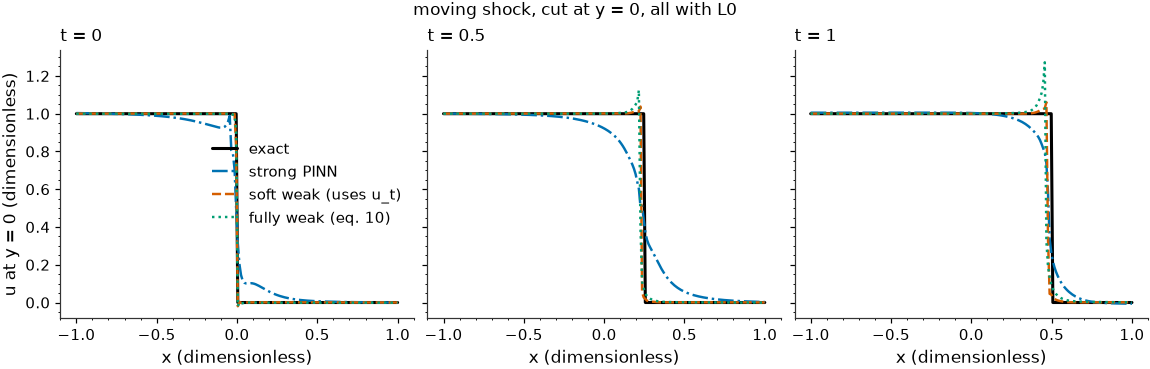

In [37]:
times = [0.0, T / 2, T]
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4), sharey=True)

for ax, time_value in zip(axes, times):
    ax.plot(x_axis, exact_solution(x_axis, time_value), color="black", linewidth=2.0, label="exact")
    for name, network in networks.items():
        u_cut = evaluate(network, x_axis, np.zeros_like(x_axis), np.full_like(x_axis, time_value))
        ax.plot(x_axis, u_cut, linestyle=line_styles[name], label=method_labels[name])
    ax.set_title(f"t = {time_value:.3g}")
    ax.set_xlabel("x (dimensionless)")

axes[0].set_ylabel("u at y = 0 (dimensionless)")
axes[0].legend()
fig.suptitle("moving shock, cut at y = 0, all with L0")
plt.show()

#### Figura 2: mapas y errores en t = T

**Figura 2.** Arriba: solución de cada método en $t = T$ con la misma escala $[0, 1]$; la línea punteada
blanca es el choque exacto en $x = 0.25$. Abajo: error absoluto con **la misma escala para los tres**,
así que un panel más oscuro es de verdad un error menor. Si un método sólo suaviza, su error es una franja
delgada sobre la línea; si mueve el choque, la franja es ancha.

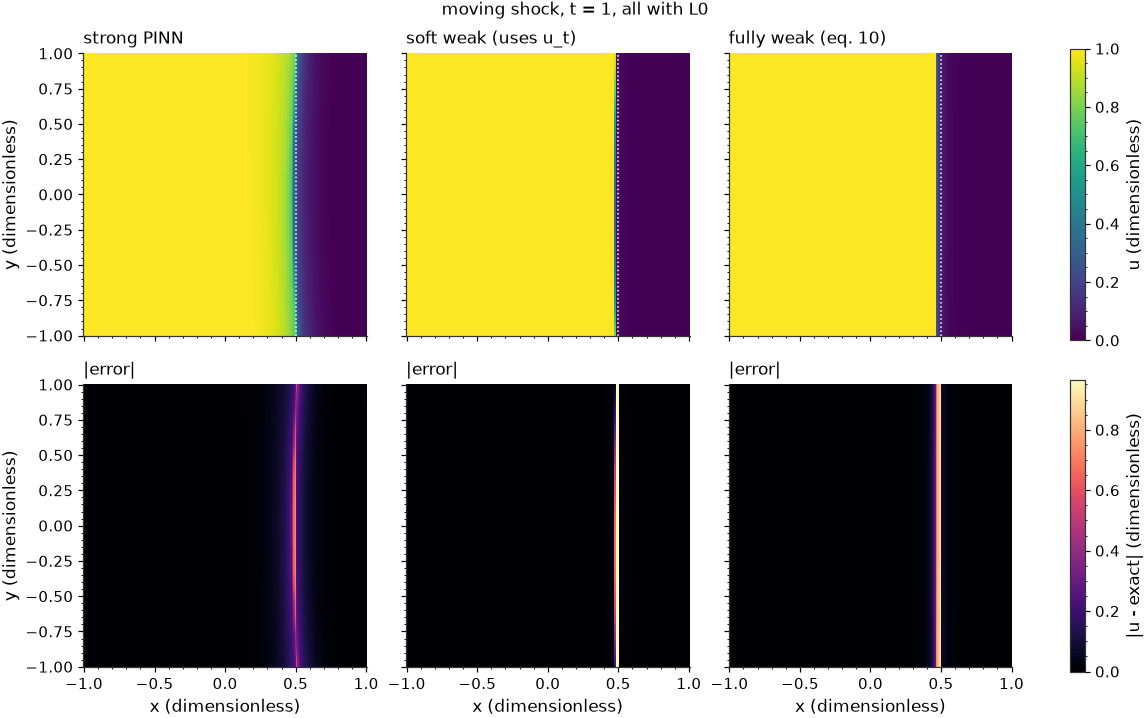

In [38]:
# Misma escala de error para los tres: si cada panel tuviera la suya, la comparación mentiría.
error_max = max(error.max() for error in errors.values())

fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.6), sharex=True, sharey=True)
for column, name in enumerate(networks):
    mesh = axes[0, column].pcolormesh(x_axis, y_axis, predictions[name], cmap="viridis", vmin=0, vmax=1, shading="auto")
    axes[0, column].axvline(shock_speed * T, color="white", linestyle=":", linewidth=1.0)
    axes[0, column].set_title(method_labels[name])
    error_mesh = axes[1, column].pcolormesh(x_axis, y_axis, errors[name], cmap="magma", vmin=0, vmax=error_max, shading="auto")
    axes[1, column].set_title("|error|")

fig.colorbar(mesh, ax=axes[0, :], label="u (dimensionless)")
fig.colorbar(error_mesh, ax=axes[1, :], label="|u - exact| (dimensionless)")
for ax in axes.flat:
    ax.set_aspect("equal")
for ax in axes[1, :]:
    ax.set_xlabel("x (dimensionless)")
for ax in axes[:, 0]:
    ax.set_ylabel("y (dimensionless)")
fig.suptitle(f"moving shock, t = {T}, all with L0")
plt.show()

#### Figura 3: error en el tiempo

**Figura 3.** Error relativo $L^1$ en función de $t$ para cada método. En $t = 0$ los tres miden lo
bien que ajustan el dato inicial. Si la curva crece con $t$, el método pierde el choque a medida que este se
mueve; si se queda plana, lo sigue.

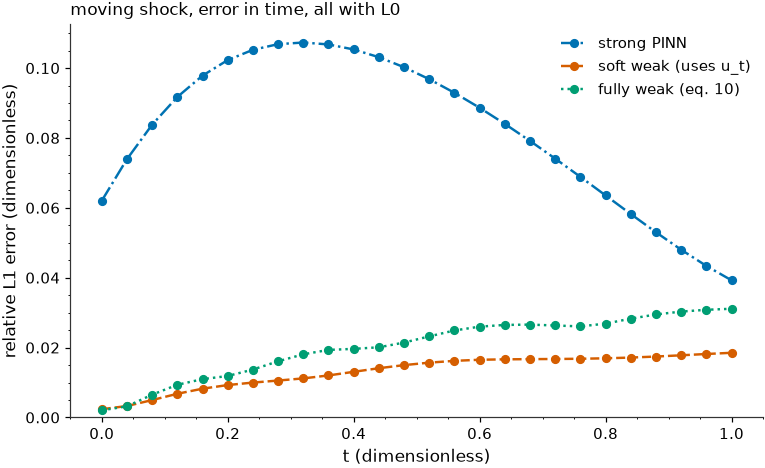

In [39]:
time_axis = np.linspace(0.0, T, 26)

fig, ax = plt.subplots()
for name, network in networks.items():
    relative_l1_in_time = []
    for time_value in time_axis:
        u_exact_now = exact_solution(X, time_value)
        u_predicted_now = evaluate(network, X, Y, np.full_like(X, time_value))
        relative_l1_in_time.append(np.abs(u_predicted_now - u_exact_now).sum() / np.abs(u_exact_now).sum())
    ax.plot(time_axis, relative_l1_in_time, linestyle=line_styles[name], marker="o", label=method_labels[name])
ax.set_xlabel("t (dimensionless)")
ax.set_ylabel("relative L1 error (dimensionless)")
ax.set_ylim(bottom=0)
ax.set_title("moving shock, error in time, all with L0")
ax.legend()
plt.show()

#### Figura 4: ajuste de los datos

**Figura 4.** Pérdida de datos (inicial + frontera) por época, en escala logarítmica. No se compara el
término físico porque $\mathrm{mean}(f^2)$ y $\mathrm{ReLU}(R)^2/\|\nabla\varphi\|^2$ miden cosas distintas;
los términos de datos sí son idénticos en los tres. Si una curva queda arriba, ese método está peleando
contra el dato.

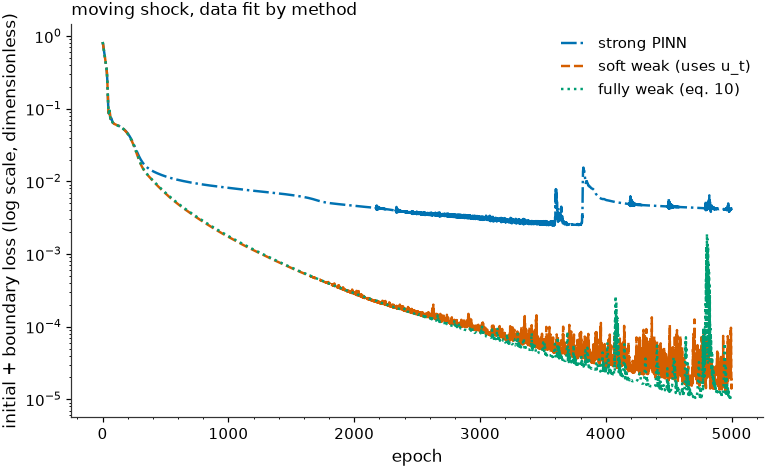

In [40]:
fig, ax = plt.subplots()
for name, history in histories.items():
    # Inicial + frontera: la única parte de la pérdida que significa lo mismo en los tres.
    data_loss = np.array(history["initial"]) + np.array(history["boundary"])
    epochs = np.arange(1, len(data_loss) + 1)
    ax.semilogy(epochs, data_loss, linestyle=line_styles[name], label=method_labels[name])
ax.set_xlabel("epoch")
ax.set_ylabel("initial + boundary loss (log scale, dimensionless)")
ax.set_title("moving shock, data fit by method")
ax.legend()
plt.show()